# One visit per patient

Sensitivity analysis for repeat attendance. Because patients can attend the ED repeatedly, this notebook restricts the analysis sample to each patient's first eligible visit and repeats the manuscript tables and Figure 2 on that cohort. Outputs are supplementary: Figure S3 and Tables S5–S9.

- Data and Counts build both cohorts: the analysis sample (every eligible visit) and the sensitivity cohort (first visit per patient). The check cell locks both against the main analysis's numbers.
- Figure S3 repeats the manuscript's Figure 2 (UpSet plot plus combined bar) on the sensitivity cohort.
- Tables S5–S8 repeat the manuscript tables on the sensitivity cohort. Their CIs are Agresti-Coull / t-based: with one visit per patient the observations are independent, so no clustering correction is needed (contrast with the main notebook).
- Table S9 reports the three pairwise agreement statistics (kappa, positive and negative specific agreement) on the sensitivity cohort, with bootstrap CIs.

In [1]:
if(!require("pacman")) install.packages("pacman")
pacman::p_load(arrow, binom, cardx, geepack, ggsci, ggupset, gt, gtsummary, patchwork, tidyverse)

# cluster-aware CI helpers shared by the analysis notebooks
source("ci_helpers.R")

Loading required package: pacman



# Data

In [2]:
ed_data <- read_parquet(
    "../MIMICED/ed_join_cc.parquet",
    col_select = c(subject_id, stay_id, intime, acuity, age, gender, race, pain,
                   disposition, length_of_stay, icd_chapter, nyu, res, acuity_out)
  ) |>
  left_join(
    read_parquet("../MIMICED/chiefcomp_clustered.parquet", col_select = c(stay_id, cluster, cluster_name)),
    by = "stay_id"
  ) |>
  mutate(
    combined_group = paste0(nyu, res, acuity_out)
  )

# Counts

In [3]:
all_visits <- ed_data |>
  filter(!is.na(acuity) & !is.na(age) & !is.na(race))

first_visits <- all_visits |>
  arrange(intime) |>
  group_by(subject_id) |>
  slice_head(n = 1) |>
  ungroup()

n <- list(
  visits        = nrow(ed_data),
  all_visits    = nrow(all_visits),
  patients      = n_distinct(all_visits$subject_id),
  first_visits  = nrow(first_visits),
  repeats       = nrow(all_visits) - nrow(first_visits),
  flagged_first = sum(first_visits$combined_group != "000"),
  flagged_all   = sum(all_visits$combined_group != "000")
)

str(n)

List of 7
 $ visits       : int 424707
 $ all_visits   : int 417723
 $ patients     : int 201106
 $ first_visits : int 201106
 $ repeats      : int 216617
 $ flagged_first: int 100568
 $ flagged_all  : int 209429


Glossary of the counts above:

- `visits` — visits with a discharge diagnosis
- `all_visits` — the analysis sample: every eligible visit (no missing acuity, age or race)
- `patients` — patients behind the analysis sample
- `first_visits` — the sensitivity cohort: first eligible visit per patient
- `repeats` — the visits the sensitivity restriction sets aside
- `flagged_first` / `flagged_all` — visits flagged by at least one algorithm, per cohort

## Check

In [4]:
checks <- tibble(
  check = c("Visits with a discharge diagnosis", "Analysis sample (visits)",
            "Analysis sample (patients)", "First visits", "Flagged first visits",
            "Flagged visits, analysis sample"),
  observed = c(n$visits, n$all_visits, n$patients, n$first_visits, n$flagged_first,
               n$flagged_all),
  expected = c(424707L, 417723L, 201106L, 201106L, 100568L, 209429L)
) |>
  mutate(result = if_else(observed == expected, "PASS", "FAIL"))

checks |>
  print()

stopifnot(all(checks$result == "PASS"))
stopifnot(n$first_visits + n$repeats == n$all_visits)

# A tibble: 6 × 4
  check                             observed expected result
  <chr>                                <int>    <int> <chr> 
1 Visits with a discharge diagnosis   424707   424707 PASS  
2 Analysis sample (visits)            417723   417723 PASS  
3 Analysis sample (patients)          201106   201106 PASS  
4 First visits                        201106   201106 PASS  
5 Flagged first visits                100568   100568 PASS  
6 Flagged visits, analysis sample     209429   209429 PASS  


# Figure S3

The manuscript's Figure 2 rebuilt on the sensitivity cohort: the upset plot of the algorithm intersections (A) and the same seven combinations stacked into one bar (B), so the segments add to the number of visits flagged by at least one algorithm.

In [5]:
jama_palette <- ggsci::pal_jama()(7)

set_levels <- c("Diagnosis", "Resources", "Triage-Acuity")

# Turn columns into lists
data_sets <- first_visits |>
  mutate(sets = pmap(list(nyu, res, acuity_out), function(nyu, res, acuity_out) {
    members <- c(
      if (nyu == 1) "Diagnosis",
      if (res == 1) "Resources",
      if (acuity_out == 1) "Triage-Acuity"
    )
    members
  }))

# Calculate counts for each combination
set_summary <- data_sets |>
  filter(lengths(sets) > 0) |>
  mutate(sets_label = sapply(sets, \(x) paste(sort(x), collapse = " + "))) |>
  count(sets_label, sort = TRUE)

# Define custom order: single sets first, then intersections by descending count
single_order <- c("Diagnosis", "Resources", "Triage-Acuity")
intersections_order <- set_summary |>
  filter(!sets_label %in% single_order) |>
  arrange(desc(n)) |>
  pull(sets_label)
custom_order <- c(single_order, intersections_order)

# Assign a display order to each combination
order_map <- tibble(
  sets_label = custom_order,
  display_order = seq_along(custom_order)
)

# Create plot data with custom ordering variable
plot_data <- data_sets |>
  filter(lengths(sets) > 0) |>
  mutate(
    sets_label = sapply(sets, \(x) paste(sort(x), collapse = " + "))
  ) |>
  left_join(order_map, by = "sets_label") |>
  mutate(
    sets_label = factor(sets_label, levels = custom_order)
  )

# Upset panel, as in the manuscript's figure 2A
figure_s3_upset <- plot_data |>
  ggplot(aes(x = sets, fill = sets_label, order = display_order)) +
  geom_bar() +
  scale_x_upset(order_by = "degree") +
  geom_text(
    stat = "count",
    aes(label = after_stat(count)),
    vjust = -1,
    size = 5,
    colour = "black",
    fontface = "bold"
  ) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.1))) +
  theme_minimal() +
  theme(
    legend.position = "none",
    panel.grid = element_blank(),
    axis.line = element_line(color = "black")
  ) +
  theme_combmatrix(
    combmatrix.label.text = element_text(
      size = 15,
      colour = "black",
      face = "bold"
    )
  ) +
  labs(
    x = "",
    y = "Visits (N)"
  ) +
  scale_fill_manual(
    values = jama_palette[c(5, 6, 4, 1, 2, 3, 7)]
  )

# Every combination stacked into one bar, as in the manuscript's figure 2B
fig_s3_counts <- plot_data |>
  count(sets_label) |>
  mutate(sets_label = factor(sets_label, levels = rev(custom_order)))

figure_s3_bar <- ggplot(fig_s3_counts, aes(x = "Total", y = n, fill = sets_label)) +
  geom_col(width = 0.9, colour = "white", linewidth = 0.3) +
  annotate(
    "text",
    x = 1,
    y = sum(fig_s3_counts$n),
    label = format(sum(fig_s3_counts$n), big.mark = ","),
    vjust = -0.6,
    size = 6,
    fontface = "bold"
  ) +
  theme_minimal() +
  labs(
    x = "",
    y = "Visits (N)"
  ) +
  scale_x_discrete(expand = expansion(add = c(0.05, 0.05))) +
  scale_y_continuous(
    expand = expansion(mult = c(0, 0.1)),
    position = "right",
    labels = scales::comma
  ) +
  # Same colours as the upset plot
  scale_fill_manual(values = jama_palette[c(5, 6, 4, 1, 2, 3, 7)] |> set_names(custom_order)) +
  theme(
    panel.grid = element_blank(),
    legend.position = "none",
    axis.line = element_line(color = "black"),
    axis.text.x = element_blank()
  )

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the ggupset package.
  Please report the issue at <https://github.com/const-ae/ggupset/issues>.”


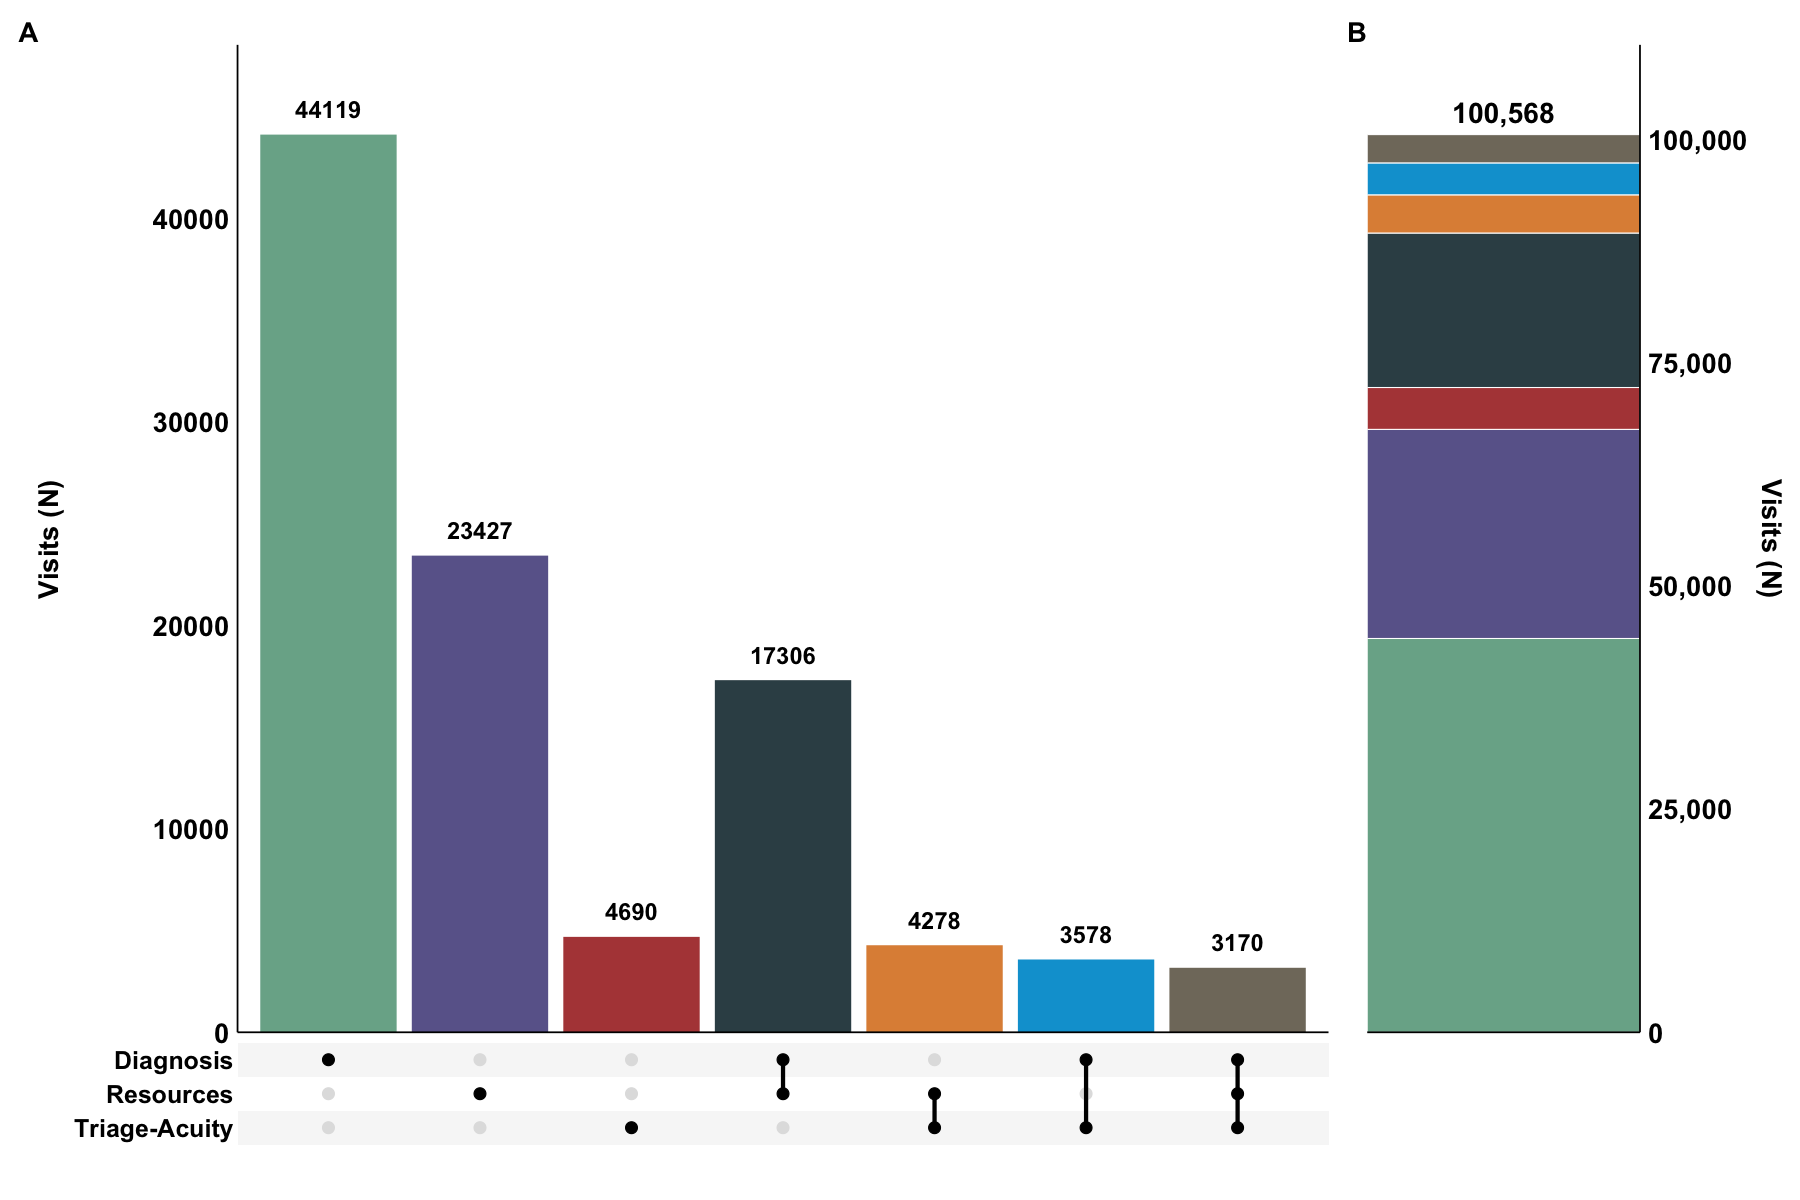

In [6]:
options(repr.plot.width = 15, repr.plot.height = 10)

Figure_S3 <- figure_s3_upset + figure_s3_bar +
  plot_layout(
    widths = c(4, 1)
  ) +
  plot_annotation(
    tag_levels = "A"
  ) &
  theme(
    plot.tag = element_text(
      color = "black",
      size = rel(1.5),
      face = "bold"
    ),
    axis.text = element_text(
      size = rel(1.5),
      colour = "black",
      face = "bold"
    ),
    axis.text.y.right = element_text(hjust = 0),
    axis.title = element_text(
      size = rel(1.5),
      colour = "black",
      face = "bold"
    )
  )

ggsave("R2_visits_figure_S3.png", plot = Figure_S3, device = "png", width = 15, height = 10, units = "in", dpi = 600)
ggsave("R2_visits_figure_S3.svg", plot = Figure_S3, device = "svg", width = 15, height = 10, units = "in")
ggsave("R2_visits_figure_S3.pdf", plot = Figure_S3, device = "pdf", width = 15, height = 10, units = "in")
Figure_S3

- Tables S5–S8 repeat the manuscript tables on the sensitivity cohort (one visit per patient), built by the same functions as the main notebook, each called once. Intervals are Agresti-Coull / t-based; independence holds by construction here.
- Table S9 reports the three pairwise agreement statistics on the same cohort, with bootstrap CIs.

In [7]:
# Helpers copied from the main analysis notebook

fmt_n <- function(x) formatC(x, big.mark = ",", format = "d")

# proportion with an Agresti-Coull interval
prop_fn <- function(x, n) {
  ci <- binom::binom.confint(sum(x), n, method = "agresti-coull")
  sprintf("%.1f [%.1f-%.1f]", ci$mean * 100, ci$lower * 100, ci$upper * 100)
}

# mean with a t-interval
summarise_mean <- function(x, digits = 1) {
  t_result <- t.test(x, conf.level = 0.95)
  fmt <- sprintf("%%.%df [%%.%df-%%.%df]", digits, digits, digits)
  sprintf(fmt, t_result$estimate, t_result$conf.int[1], t_result$conf.int[2])
}

# median with quartiles
summarise_median <- function(x) {
  q1  <- quantile(x, 0.25, names = FALSE, na.rm = TRUE)
  med <- median(x, na.rm = TRUE)
  q3  <- quantile(x, 0.75, names = FALSE, na.rm = TRUE)
  sprintf("%d [%d-%d]", med, q1, q3)
}

# cluster names travel with the labels (cluster_name in chiefcomp_clustered.parquet)

# the exclusive algorithm combinations, in the order the manuscript's columns use
combo_codes <- c("100", "010", "001", "110", "011", "101", "111")
combo_names <- c(
  "Diagnosis", "Resource", "Triage Acuity",
  "Diagnosis+Resources", "Resources+Triage Acuity", "Diagnosis+Triage Acuity",
  "Diagnosis+Resources+Triage Acuity"
)

# save the .docx and show the table in the notebook
show_save <- function(tbl_gt, filename) {
  gtsave(tbl_gt, filename = filename)
  tbl_gt |>
    as_raw_html(inline_css = TRUE) |>
    as.character() |>
    IRdisplay::display_html()
  invisible(tbl_gt)
}

## Table S5

In [8]:
# Table S1 — age, sex and self-reported race, as in the manuscript

table_1_fn <- function(data, label, filename) {
  table_1_data <- data |>
    select(age, gender, race) |>
    mutate(
      cohort = label,
      race = case_when(
        str_detect(race, "WHITE") ~ "White",
        str_detect(race, "BLACK") ~ "Black",
        str_detect(race, "HISPANIC") ~ "Hispanic/Latino",
        str_detect(race, "ASIAN") ~ "Asian",
        TRUE ~ "Other"
      ),
      race = as_factor(race),
      gender = case_when(
        gender == "M" ~ "Male",
        gender == "F" ~ "Female"
      ),
      gender = as_factor(gender)
    )

  table_1 <- table_1_data |>
    mutate(
      age_mean = age,
      age_median = age
    ) |>
    select(-age) |>
    tbl_summary(
      by = cohort,
      include = c(age_mean, age_median, gender, race),
      label = list(
        age_mean ~ "Age (Years, mean)",
        age_median ~ "(Years, median)",
        gender ~ "Sex (%)",
        race ~ "Self-reported Race (%)"
      ),
      statistic = list(
        age_mean ~ "{mean}",
        age_median ~ "{median} ({min}-{max})",
        all_categorical() ~ "{p}%"
      ),
      sort = list(gender ~ "frequency", race ~ "frequency"),
      digits = list(everything() ~ c(0, 0)),
      missing = "no"
    ) |>
    bold_labels() |>
    add_ci(
      include = c(age_mean, all_categorical()),
      method = list(
        age_mean ~ "t.test",
        all_categorical() ~ "agresti.coull"
      ),
      statistic = list(
        age_mean ~ "{conf.low}, {conf.high}",
        all_categorical() ~ "{conf.low}%, {conf.high}%"
      ),
      pattern = "{stat} [{ci}]",
      conf.level = 0.95
    ) |>
    modify_header(all_stat_cols() ~ "**{level}**") |>
    modify_footnote_header(
      footnote = "Confidence interval (CI) for categorical variables is computed using Agresti-Coull interval.",
      columns = all_stat_cols(),
      replace = TRUE
    ) |>
    modify_footnote_body(
      footnote = "For clarity, self-reported races have been collapsed.",
      columns = "label",
      rows = variable == "race" & row_type == "label",
      replace = TRUE
    )

  show_save(table_1 |> as_gt(), filename)
}

In [9]:
table_1_fn(first_visits, "One visit per patient", "R2_visits_table_S5.docx")

Abbreviation: CI = Confidence Interval
1 Confidence interval (CI) for categorical variables is computed using Agresti-Coull interval.
"2 For clarity, self-reported races have been collapsed."


## Table S6

In [10]:
# Table S2 — characteristics of all visits and of each algorithm combination

table_2_fn <- function(data, filename) {
  d <- data |>
    select(age, gender, pain, acuity, disposition, length_of_stay, combined_group) |>
    mutate(
      admitted = if_else(disposition == "ADMITTED", 1, 0),
      home     = if_else(disposition == "HOME", 1, 0),
      female   = if_else(gender == "F", 1, 0),
      acuity   = as.integer(acuity),
      pain     = as.integer(pain)
    )

  # the same summary for one column of the table
  summarise_block <- function(g) {
    g |>
      summarise(
        `Number of visits (N)` = fmt_n(n()),
        `Proportion (%, [95% CI])` = prop_fn(n(), nrow(d)),
        `Age (years, mean [95% CI])` = summarise_mean(age),
        `Female (%, [95% CI])` = prop_fn(female, n()),
        `Pain (/10, median [IQR])` = summarise_median(pain),
        `Acuity (/5, median [IQR])` = summarise_median(acuity),
        `Length of stay (mins, mean [95% CI])` = summarise_mean(length_of_stay, digits = 0),
        `Discharged home (%, [95% CI])` = prop_fn(home, n()),
        `Admitted to hospital (%, [95% CI])` = prop_fn(admitted, n()),
        .groups = "drop"
      )
  }

  table_2 <- d |>
    filter(combined_group %in% c("000", combo_codes)) |>
    group_by(combined_group) |>
    summarise_block() |>
    pivot_longer(
      cols      = -combined_group,
      names_to  = "Measure",
      values_to = "value"
    ) |>
    mutate(
      combined_group = factor(
        combined_group,
        levels = c("000", combo_codes),
        labels = c("Not identified by any algorithm", combo_names)
      )
    ) |>
    pivot_wider(
      names_from  = combined_group,
      values_from = value,
      names_sort  = TRUE
    ) |>
    mutate(across(
      c(Resource, `Diagnosis+Resources`, `Resources+Triage Acuity`,
        `Diagnosis+Resources+Triage Acuity`),
      \(x) if_else(Measure == "Admitted to hospital (%, [95% CI])", "NA", x)
    ))

  table_2_gt <- table_2 |>
    gt() |>
    tab_footnote(
      footnote = "95% confidence intervals (CI): Agresti-Coull for proportions; t-distribution for means",
      locations = cells_body(columns = Measure, rows = str_detect(Measure, fixed("95% CI")))
    ) |>
    tab_footnote(
      footnote = "Only female/male are reported in the data",
      locations = cells_body(columns = Measure, rows = Measure == "Female (%, [95% CI])")
    ) |>
    tab_footnote(
      footnote = "Emergency Severity Index, 1 = most severe",
      locations = cells_body(columns = Measure, rows = Measure == "Acuity (/5, median [IQR])")
    ) |>
    tab_footnote(
      footnote = "NA; Not applicable. The Resource algorithm excludes visits that were admitted by design",
      locations = cells_body(
        columns = c(Resource, `Diagnosis+Resources`, `Resources+Triage Acuity`,
                    `Diagnosis+Resources+Triage Acuity`),
        rows = Measure == "Admitted to hospital (%, [95% CI])"
      )
    )

  show_save(table_2_gt, filename)
}

In [11]:
table_2_fn(first_visits, "R2_visits_table_S6.docx")

1 95% confidence intervals (CI): Agresti-Coull for proportions; t-distribution for means
2 Only female/male are reported in the data
"3 Emergency Severity Index, 1 = most severe"
4 NA; Not applicable. The Resource algorithm excludes visits that were admitted by design


## Table S7

In [12]:
# Tables S3 and S4 — top three values overall and per algorithm combination

rank_table_fn <- function(data, var, codes, code_labels, filename) {
  d <- data |>
    mutate(cluster = cluster_name) |>
    select(all_of(c(var, "combined_group")))

  top_3 <- function(df) {
    df |>
      count(.data[[var]]) |>
      mutate(pct = n / sum(n) * 100) |>
      arrange(desc(pct)) |>
      slice_head(n = 3) |>
      mutate(cell = sprintf("%s (%.1f%%)", .data[[var]], pct)) |>
      pull(cell)
  }

  columns <- c(
    list(Overall = top_3(d)),
    set_names(
      map(codes, \(code) top_3(d |> filter(combined_group == code))),
      code_labels
    )
  )

  tbl <- bind_cols(
    tibble(Rank = c("1st", "2nd", "3rd")),
    as_tibble(columns)
  )

  show_save(tbl |> gt(), filename)
}

In [13]:
rank_table_fn(first_visits, "cluster", combo_codes, combo_names,
               "R2_visits_table_S7.docx")

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" scope="col" id="Rank" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: left;" bgcolor="#FFFFFF" valign="bottom" align="left">Rank 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" scope="col" id="Overall" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: left;" bgcolor="#FFFFFF" valign="bottom" align="left">Overall 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" scope="col" id="Diagnosis" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: left;" bgcolor="#FFFFFF" valign="bottom" align="left">Diagnosis 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" scope="col" id="Resource" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: left;" bgcolor="#FFFFFF" valign="bottom" align="left">Resource 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" scope="col" id="Triage-Acuity" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: left;" bgcolor="#FFFFFF" valign="bottom" align="left">Triage Acuity 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" scope="col" id="Diagnosis+Resources"

## Table S8

In [14]:
rank_table_fn(first_visits, "icd_chapter", combo_codes, combo_names,
               "R2_visits_table_S8.docx")

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" scope="col" id="Rank" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: left;" bgcolor="#FFFFFF" valign="bottom" align="left">Rank 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" scope="col" id="Overall" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: left;" bgcolor="#FFFFFF" valign="bottom" align="left">Overall 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" scope="col" id="Diagnosis" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: left;" bgcolor="#FFFFFF" valign="bottom" align="left">Diagnosis 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" scope="col" id="Resource" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: left;" bgcolor="#FFFFFF" valign="bottom" align="left">Resource 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" scope="col" id="Triage-Acuity" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: left;" bgcolor="#FFFFFF" valign="bottom" align="left">Triage Acuity 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" scope="col" id="Diagnosis+Resources"

## Table S9

The three pairwise kappas for the sensitivity cohort, with bootstrap CIs, alongside positive and negative specific agreement (same bootstrap).

In [15]:
# Pairwise agreement for the one-visit cohort (kappa and positive and negative
# specific agreement, reported together because kappa
# depends on prevalence); CIs by bootstrap, see agreement_boot_ci() in ci_helpers.R
ci_fmt <- function(est, lo, hi, scale = 1, digits = 3) {
  fmt <- sprintf("%%.%df [%%.%df-%%.%df]", digits, digits, digits)
  sprintf(fmt, scale * est, scale * lo, scale * hi)
}

agree_row <- function(data, r1, r2, label) {
  ag <- agreement_boot_ci(data[[r1]], data[[r2]], data$subject_id)
  tibble(
    Measure = label,
    `Kappa [95% CI]` = ci_fmt(ag$kappa, ag$kappa_lo, ag$kappa_hi),
    `Positive specific agreement (%) [95% CI]` = ci_fmt(ag$psa, ag$psa_lo, ag$psa_hi, scale = 100, digits = 1),
    `Negative specific agreement (%) [95% CI]` = ci_fmt(ag$nsa, ag$nsa_lo, ag$nsa_hi, scale = 100, digits = 1)
  )
}

table_9 <- bind_rows(
  agree_row(first_visits, "nyu", "acuity_out", "Diagnosis vs Triage-Acuity"),
  agree_row(first_visits, "nyu", "res", "Diagnosis vs Resources"),
  agree_row(first_visits, "acuity_out", "res", "Resources vs Triage-Acuity")
)

tbl_gt <- table_9 |>
  gt() |>
  tab_spanner(label = "One visit per patient", columns = -Measure) |>
  tab_footnote(
    footnote = "95% confidence intervals (CI) by bootstrap"
  ) |>
  tab_footnote(
    footnote = "Positive specific agreement, 100 x 2a/(2a+b+c), and negative specific agreement, 100 x 2d/(2d+b+c), where a is the number of visits flagged by both algorithms, d the number flagged by neither, and b and c the visits flagged by only one"
  )

gtsave(tbl_gt, filename = "R2_visits_table_S9.docx")

tbl_gt |>
  as_raw_html(inline_css = TRUE) |>
  as.character() |>
  IRdisplay::display_html()

95% confidence intervals (CI) by bootstrap
"Positive specific agreement, 100 x 2a/(2a+b+c), and negative specific agreement, 100 x 2d/(2d+b+c), where a is the number of visits flagged by both algorithms, d the number flagged by neither, and b and c the visits flagged by only one"
